# This is a notebook that predicts customer churn for a tel communication company

## Data is coming from kaggle and the steps are:
- Environment creation
- Data collection
- Data preparation
- Exploratory Data Analysis (EDA)
- Feature engineering
- Model development
- Results

### Step 0: Environment creation
In this step the required packages will be downloaded and imported into the working environment

In [1]:
#%pip install numpy; pandas; matplotlib; scikit-learn; kagglehub

In [2]:
import pandas as pd
import sklearn
import kagglehub

import matplotlib.pyplot as plt


c:\D_Folder\GitFiles\DataScienceProjects\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Step 1: Data fetching

In [3]:
handle = 'blastchar/telco-customer-churn'
path = 'Data'

dataset = kagglehub.dataset_download(handle=handle, output_dir=path)

df = pd.read_csv(f'{path}\\WA_Fn-UseC_-Telco-Customer-Churn.csv')

print(df.head())

print(f"Data columns: {df.columns}")

print(df.dtypes)

print(df.isna().sum())


   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

#### Step 1 conclusions

- There are no missing values
- Dataset contains 21 columns
- Most columns are yes/no which can be turned into boolean 1/0 as "senior" column
- There are some string columns that needs to be encoded
- Total charges column is of string type and should be converted to float

### Step 2: Data Preparation

In [4]:
#Transform Yes/No columns into 1/0

#Determine Yes/No(Binary) Columns 
yes_no = {"Yes", "No"}
binary_cols = [
    col for col in df.select_dtypes(include=['object', 'string']).columns
    if set(df[col].unique()).issubset(yes_no)
]
print(f"Binary columns: f{binary_cols}")

#Determine non-binary columns(Yes/No/Third Option) for visualization
non_binary_cols = [
    col for col in df.select_dtypes(include=['string']).columns
    if not set(df[col].unique()).issubset(yes_no)
]
print(f"Non Binary Columns: f{non_binary_cols}")

#Binary columns replacement
df[binary_cols] = df[binary_cols].replace({'Yes': 1, 'No':0}).astype(int)
#Gender columns replacement
df['gender'] = df['gender'].replace({'Male':1, 'Female':0}).astype(int)

#Set total charges dtype to float
df = df[df["TotalCharges"].astype("string").str.strip().ne("")].copy()
df["TotalCharges"] = df["TotalCharges"].astype(float)

print(df['OnlineSecurity'].value_counts())
print(df['Partner'].value_counts())
print(df['gender'].value_counts())
print(df['TotalCharges'].value_counts())

df.describe()


Binary columns: f['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']
Non Binary Columns: f['customerID', 'gender', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod', 'TotalCharges']
OnlineSecurity
No                     3497
Yes                    2015
No internet service    1520
Name: count, dtype: int64
Partner
0    3639
1    3393
Name: count, dtype: int64
gender
1    3549
0    3483
Name: count, dtype: int64
TotalCharges
20.20      11
19.75       9
19.90       8
20.05       8
19.65       8
           ..
1990.50     1
7362.90     1
346.45      1
306.60      1
6844.50     1
Name: count, Length: 6530, dtype: int64


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn
count,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000
mean,0.504693,0.162400,0.482509,0.298493,32.421786,0.903299,0.592719,64.798208,2283.300441,0.265785
std,0.500014,0.368844,0.499729,0.457629,24.545260,0.295571,0.491363,30.085974,2266.771362,0.441782
min,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,18.250000,18.800000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,9.000000,1.000000,0.000000,35.587500,401.450000,0.000000
50%,1.000000,0.000000,0.000000,0.000000,29.000000,1.000000,1.000000,70.350000,1397.475000,0.000000
75%,1.000000,0.000000,1.000000,1.000000,55.000000,1.000000,1.000000,89.862500,3794.737500,1.000000
max,1.000000,1.000000,1.000000,1.000000,72.000000,1.000000,1.000000,118.750000,8684.800000,1.000000


### Step 3: Exploratory Data Analysis

Text(0, 0.5, 'Mean Churn')

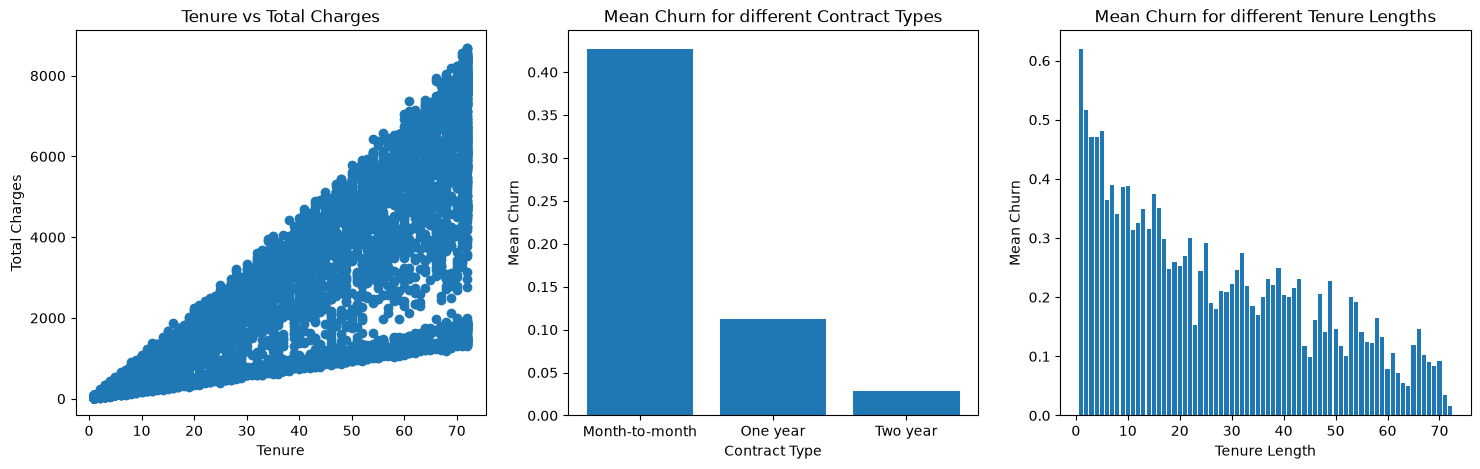

In [ ]:
fig = plt.figure(figsize=(18, 5))

#Create a scatter plot to visualize the relationship between tenure and total charge
plt.subplot(131)
plt.scatter(x=df['tenure'], y=df['TotalCharges'])
plt.title('Tenure vs Total Charges')
plt.xlabel('Tenure')
plt.ylabel('Total Charges')

#Create a barplot to show a histogram of churn rate by contract type
plt.subplot(132)
df_churn_contract = df.groupby('Contract')['Churn'].mean().reset_index()
plt.bar(x=df_churn_contract['Contract'], height=df_churn_contract['Churn'])
plt.title('Mean Churn for different Contract Types')
plt.xlabel('Contract Type')
plt.ylabel('Mean Churn')

#Create a barplot to show a histogram of churn rate by Tenure
plt.subplot(133)
df_churn_tenure = df.groupby('tenure')['Churn'].mean().reset_index()
plt.bar(x=df_churn_tenure['tenure'], height=df_churn_tenure['Churn'])
plt.title("Mean Churn for different Tenure Lengths")
plt.xlabel("Tenure Length")
plt.ylabel("Mean Churn")